# Quantum Billiards and Scars

We solve $-\nabla^2\psi = E\psi$ with $\psi = 0$ on the wall by finite differences on a square grid
of spacing $h$ (`billiard.py`). The wall is put in with a **mask**: only grid points strictly
inside the shape are unknowns, and every other point is held at $\psi = 0$. Localization and
level-statistics tools are in `spectra.py`; fast unit checks are in `test_billiard.py`.

Two claims are treated as hypotheses to be tested, not as known facts: that some stadium
eigenstates are scarred by periodic orbits, and that the stadium spectrum follows
random-matrix (Wigner) statistics. Each section ends with a printed **CHECK** line, and
section 7 collects them.

In [1]:
import numpy as np
import matplotlib.pyplot as plt

from billiard import (grid, rectangle_mask, stadium_mask, quarter_stadium_mask, stadium_area,
                      quarter_stadium_perimeter, laplacian_matrix, apply_laplacian, solve,
                      eigenvalues, residual, rect_exact_discrete, rect_exact_continuum)
from spectra import (ipr, unfold_weyl, unfold_fit, spacings, compare,
                     poisson_pdf, wigner_pdf, poisson_cdf, wigner_cdf)

checks = {}
def check(name, ok):
    checks[name] = bool(ok)
    print(f"CHECK {name}:", "PASS" if ok else "FAIL")

def gallery(psi, idx, titles, ncols=4, size=(3, 1.6)):
    nrows = -(-len(idx) // ncols)
    fig, axes = plt.subplots(nrows, ncols, figsize=(size[0] * ncols, size[1] * nrows))
    for ax in axes.flat:
        ax.axis("off")
    for ax, n, t in zip(axes.flat, idx, titles):
        ax.imshow(psi[n] ** 2, origin="lower", cmap="inferno")
        ax.set_title(t, fontsize=8)
    plt.tight_layout()
    plt.show()

## 1. One stencil, written two ways

The second difference in each direction gives the five-point stencil
$$-\nabla^2\psi_{i,j} \approx \frac{4\psi_{i,j} - \psi_{i+1,j} - \psi_{i-1,j} - \psi_{i,j+1} - \psi_{i,j-1}}{h^2},$$
the same stencil as the Jacobi relaxation of Laplace's equation in notebook 04, Problem 2.
Relaxation cannot find eigenvalues, though: here $E$ is unknown and nothing drives $\psi$ away
from zero. So the solver writes the stencil as a sparse matrix
(`kron` of 1D second-difference matrices, cut down to the interior points) and hands it to
`eigsh` in shift-invert mode about $\sigma = 0$, which returns the lowest eigenpairs.

`apply_laplacian` writes the same stencil with numpy slicing, exactly as in Problem 2. It
shares no code with the matrix. Every solved state is fed back through it, and the residual
$\|-\nabla^2\psi - E\psi\| / (E\|\psi\|)$ must sit at round-off level.

In [2]:
A_ST = stadium_area()
h_st = 0.02
X, Y = grid(2, 1, h_st)
mask_st = stadium_mask(X, Y)
E_st, psi_st = solve(mask_st, h_st, 300)
res = residual(E_st, psi_st, h_st, mask_st)

print(f"stadium a = r = 1: {mask_st.sum()} unknowns, 300 states, E up to {E_st[-1]:.0f}")
print(f"grid points per wavelength at the top state: {2 * np.pi / np.sqrt(E_st[-1]) / h_st:.1f}")
print(f"max residual over all 300 states: {res.max():.1e}")
check("1 (slicing residual < 1e-8 for every state)", res.max() < 1e-8)

stadium a = r = 1: 17725 unknowns, 300 states, E up to 553
grid points per wavelength at the top state: 13.4
max residual over all 300 states: 7.3e-13
CHECK 1 (slicing residual < 1e-8 for every state): PASS


## 2. The rectangle, where the answer is known

Two things can be checked, and they test different things:

* **The code.** For the five-point matrix on an $N_x h \times N_y h$ rectangle the eigenvalues
  are known exactly:
  $E = \frac{4}{h^2}\left[\sin^2\frac{n\pi}{2N_x} + \sin^2\frac{m\pi}{2N_y}\right]$.
  The solver must reproduce them to round-off.
* **The physics.** As $h \to 0$ these approach $\pi^2(n^2/L_x^2 + m^2/L_y^2)$, with error $O(h^2)$.

The rectangle is $N_x : N_y = 233 : 144$, a ratio of consecutive Fibonacci numbers and so
$\approx$ the golden ratio. On a grid every ratio is rational; this is the "most irrational"
one available, which keeps the accidental degeneracies of $n^2 + m^2$ away.

233 x 144 grid, lowest 50: max relative deviation from the exact discrete formula = 9.4e-14
CHECK 2a (solver = exact discrete spectrum, rtol 1e-9): PASS


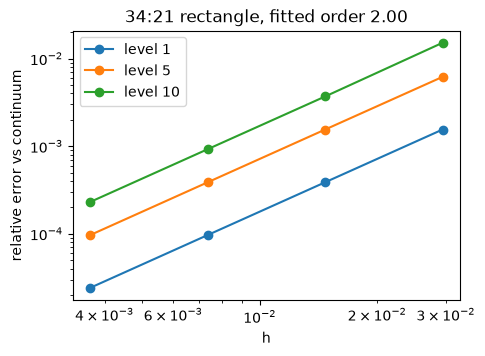

CHECK 2b (convergence order 2 +- 0.05): PASS
lowest 1000 continuum levels: coincident pairs in the square = 599, in the 233:144 rectangle = 0


In [3]:
Nx, Ny = 233, 144
h_r = 1 / Nx                                   # L_x = 1, L_y = 144/233
E_r, psi_r = solve(rectangle_mask(Nx, Ny), h_r, 50)
dev = np.max(np.abs(E_r / rect_exact_discrete(Nx, Ny, h_r, 50) - 1))
print(f"233 x 144 grid, lowest 50: max relative deviation from the exact discrete formula = {dev:.1e}")
check("2a (solver = exact discrete spectrum, rtol 1e-9)", dev < 1e-9)

hs, errs = [], []
for s in (1, 2, 4, 8):
    nx, ny = 34 * s, 21 * s
    h = 1 / nx
    E, _ = solve(rectangle_mask(nx, ny), h, 10)
    hs.append(h)
    errs.append(np.abs(E / rect_exact_continuum(1, ny * h, 10) - 1))
errs = np.array(errs)
slope = np.polyfit(np.log(hs), np.log(errs.mean(axis=1)), 1)[0]

plt.figure(figsize=(5, 3.5))
for n in (0, 4, 9):
    plt.loglog(hs, errs[:, n], "o-", label=f"level {n + 1}")
plt.xlabel("h"); plt.ylabel("relative error vs continuum"); plt.legend()
plt.title(f"34:21 rectangle, fitted order {slope:.2f}")
plt.show()
check("2b (convergence order 2 +- 0.05)", abs(slope - 2) < 0.05)

def n_degenerate(E):
    return int(np.sum(np.diff(E) < 1e-9 * E[1:]))
deg_sq = n_degenerate(rect_exact_continuum(1, 1, 1000))
deg_fib = n_degenerate(rect_exact_continuum(1, 144 / 233, 1000))
print(f"lowest 1000 continuum levels: coincident pairs in the square = {deg_sq}, in the 233:144 rectangle = {deg_fib}")

## 3. The stadium

Same solver, different mask: a Bunimovich stadium with half-length $a = 1$ of the straight
sides and radius $r = 1$ of the caps. Below are 24 of the 300 states, evenly spaced in index.

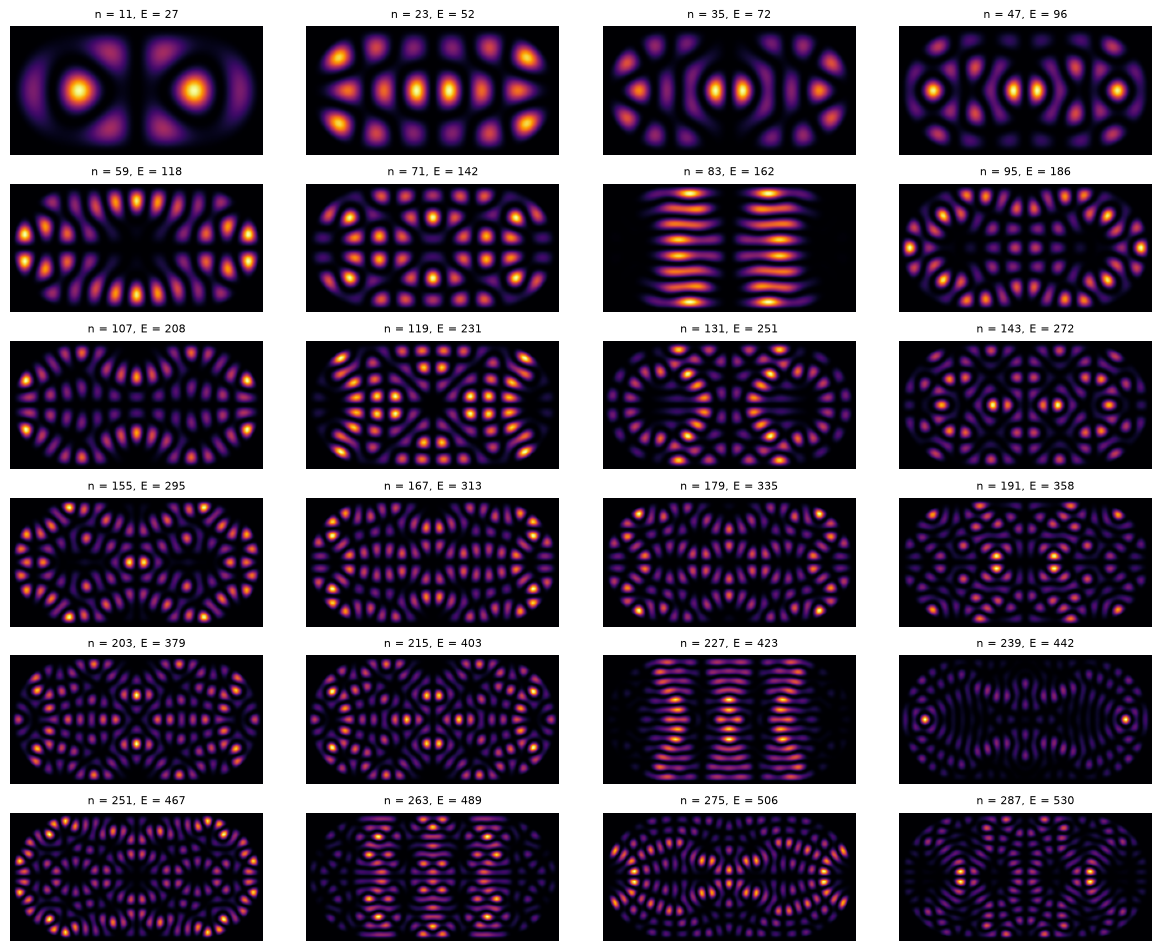

In [4]:
idx = np.arange(11, 300, 12)[:24]
gallery(psi_st, idx, [f"n = {n}, E = {E_st[n]:.0f}" for n in idx])

## 4. Measuring localization: the inverse participation ratio

With $\sum_i \psi_i^2 h^2 = 1$, the IPR is $I = \sum_i \psi_i^4 h^2$ and $I \cdot A$ is
dimensionless. Two reference values:

* rectangle: $\psi \propto \sin\sin$ gives $I \cdot A = (3/2)^2 = 9/4$ for every state;
* a Gaussian random wave (the model of an ergodic state) gives $\langle\psi^4\rangle = 3\langle\psi^2\rangle^2$, so $I \cdot A \approx 3$.

The value 3 ignores the walls, so we measure a fair ergodic reference directly. Each random
state is a superposition of the stadium's own eigenstates in a window, with Gaussian random
coefficients. It lives in the same space and obeys the same walls, but it has no reason to
follow any orbit.

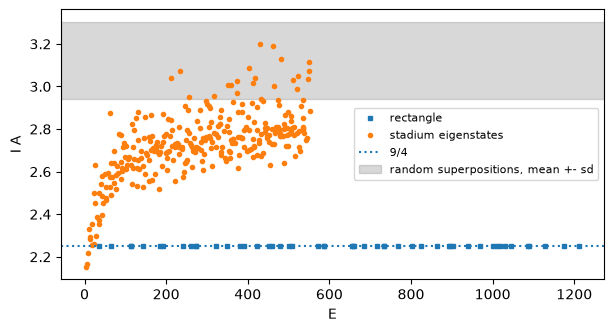

rectangle I A: 2.250000 .. 2.250000
stadium eigenstates (n >= 30): median 2.752, max 3.198
random superpositions:  3.122 +- 0.182
CHECK 4 (rectangle I A = 9/4 to 1e-6): PASS


In [5]:
I_st = ipr(psi_st, h_st) * A_ST
I_r = ipr(psi_r, h_r) * (Nx * h_r) * (Ny * h_r)

rng = np.random.default_rng(0)
LOW = 30                                # skip the lowest states, which are smooth and not yet semiclassical
c = rng.normal(size=(500, 300 - LOW))
c /= np.linalg.norm(c, axis=1, keepdims=True)
psi_rand = np.tensordot(c, psi_st[LOW:], 1)
I_rand = ipr(psi_rand, h_st) * A_ST

plt.figure(figsize=(7, 3.5))
plt.plot(E_r, I_r, "s", ms=3, label="rectangle")
plt.plot(E_st, I_st, ".", label="stadium eigenstates")
plt.axhline(9 / 4, color="C0", ls=":", label="9/4")
plt.axhspan(I_rand.mean() - I_rand.std(), I_rand.mean() + I_rand.std(), color="gray", alpha=0.3,
            label="random superpositions, mean +- sd")
plt.xlabel("E"); plt.ylabel("I A"); plt.legend(fontsize=8)
plt.show()

print(f"rectangle I A: {I_r.min():.6f} .. {I_r.max():.6f}")
print(f"stadium eigenstates (n >= {LOW}): median {np.median(I_st[LOW:]):.3f}, max {I_st[LOW:].max():.3f}")
print(f"random superpositions:  {I_rand.mean():.3f} +- {I_rand.std():.3f}")
check("4 (rectangle I A = 9/4 to 1e-6)", np.allclose(I_r, 9 / 4, atol=1e-6))

**What this shows.** Stadium eigenstates scatter around $I A \approx 2.75$, which is *below* the
random-superposition value of $\approx 3.1$. At these energies a typical stadium eigenstate is
therefore spread *more* evenly than a random wave obeying the same walls. The gap closes slowly
as $E$ grows, so this is a low-energy effect, not a limit. Even the highest-IPR states only reach
about 3.2. So a raw IPR number does not prove a state is scarred. It is still useful as a
**ranking** within the stadium's own states, and section 5 tests whether the top of that
ranking really is scarred.

## 5. The 20 most localized stadium states

The stadium's two simplest periodic orbits give each candidate a region it should crowd:

* the **horizontal orbit** along the axis $y = 0$, bouncing between the two caps: strip $|y| < 0.2$;
* the **bouncing-ball** family, bouncing vertically between the flat walls: region $|x| < a$.
  (This is a one-parameter family of marginally stable orbits, not an isolated unstable one.
  Its states are a well-known non-generic part of the stadium.)

A state counts as scarred on an orbit if its weight $\int_{\rm region}|\psi|^2$ is more than
$4\sigma$ above the random-superposition distribution of that weight.

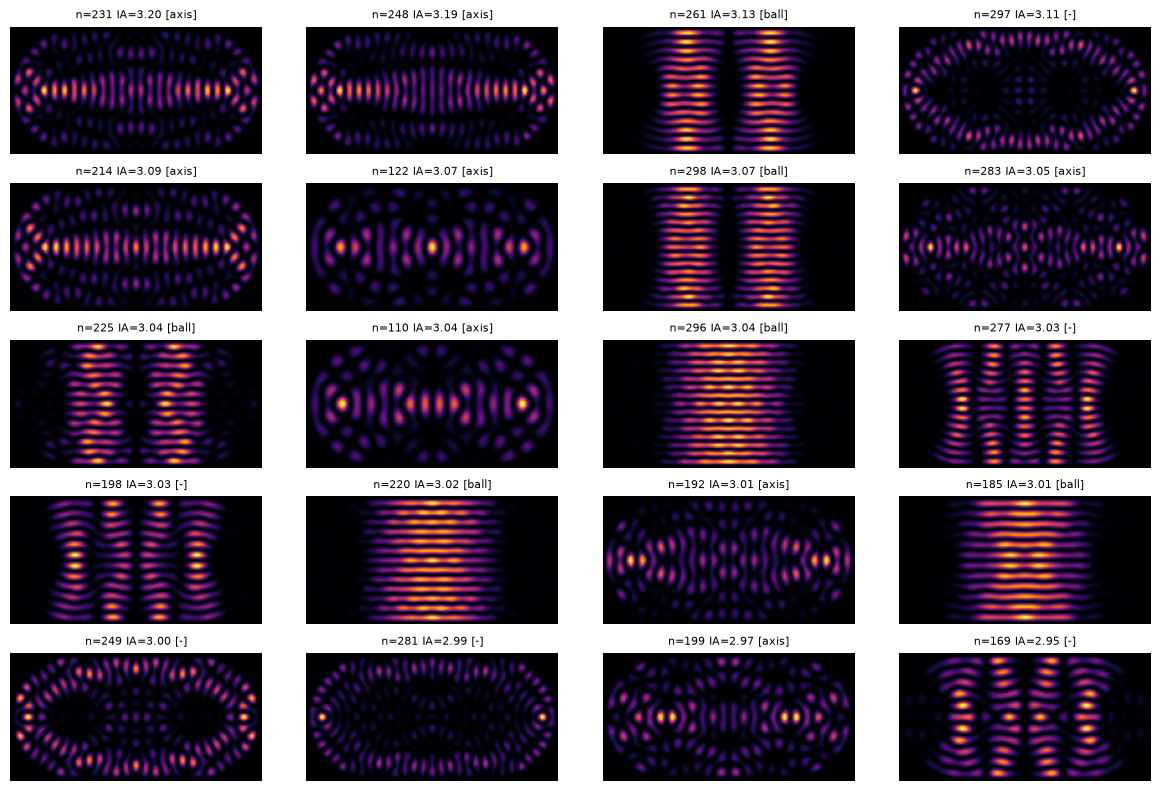

axis: random weight 0.217 +- 0.031, threshold 0.340
ball: random weight 0.560 +- 0.039, threshold 0.715
scarred fraction: top-20 by IPR = 0.70, all states n >= 30 = 0.19
top-20 labels: ['axis', 'axis', 'ball', '-', 'axis', 'axis', 'ball', 'axis', 'ball', 'axis', 'ball', '-', '-', 'ball', 'axis', 'ball', '-', '-', 'axis', '-']
CHECK 5 (>= half of the top 20 scarred, both orbits present, top-20 rate > 2x overall): PASS


In [6]:
regions = {"axis": np.abs(Y) < 0.2, "ball": np.abs(X) < 1}
weight = lambda P, r: (P**2 * r).sum(axis=(-2, -1)) * h_st**2
thresh = {k: weight(psi_rand, r).mean() + 4 * weight(psi_rand, r).std() for k, r in regions.items()}
W = {k: weight(psi_st, r) for k, r in regions.items()}

def label(n):
    hits = [k for k in regions if W[k][n] > thresh[k]]
    return "+".join(hits) if hits else "-"

top = np.argsort(I_st[LOW:])[::-1][:20] + LOW
gallery(psi_st, top, [f"n={n} IA={I_st[n]:.2f} [{label(n)}]" for n in top])

for k in regions:
    w = weight(psi_rand, regions[k])
    print(f"{k:4s}: random weight {w.mean():.3f} +- {w.std():.3f}, threshold {thresh[k]:.3f}")
scarred = np.array([label(n) != "-" for n in range(300)])
frac_top, frac_all = scarred[top].mean(), scarred[LOW:].mean()
print(f"scarred fraction: top-20 by IPR = {frac_top:.2f}, all states n >= {LOW} = {frac_all:.2f}")
print("top-20 labels:", [label(n) for n in top])
check("5 (>= half of the top 20 scarred, both orbits present, top-20 rate > 2x overall)",
      frac_top >= 0.5 and frac_top > 2 * frac_all
      and any("axis" in label(n) for n in top) and any("ball" in label(n) for n in top))

The states marked **axis** are the horizontal-orbit scars. They have a bright ridge along
$y = 0$ running from cap to cap, with $|\psi|^2$ elsewhere well below the ergodic level. The **ball** states
are vertical standing waves confined between the flat walls. Unmarked states in the top 20
mostly hug the curved boundary. These are whispering-gallery-like states, a structure our two
regions do not test for.

For comparison, every rectangle state has $I A = 9/4$ exactly. A rectangle has nothing to rank,
because each eigenstate is a product of sines that fills the whole table in the same way.

## 6. Push harder: level spacings

Bohigas–Giannoni–Schmit (1984) conjecture that a chaotic system's level spacings follow random-matrix
statistics. With levels unfolded to unit mean spacing,

* integrable (rectangle): **Poisson**, $P(s) = e^{-s}$; levels happily sit on top of each other;
* chaotic (stadium): **Wigner** (GOE surmise), $P(s) = \frac{\pi s}{2} e^{-\pi s^2/4}$, with level repulsion $P(0) = 0$.

**Quarter stadium.** The full stadium has two reflection symmetries, so its spectrum is four
independent spectra overlaid. Mixed together, those look closer to Poisson. Walls on the two
symmetry axes keep just one class (odd–odd).

**Unfolding, two ways.** (i) Weyl's law with the perimeter term,
$N(E) \approx AE/4\pi - L\sqrt{E}/4\pi$, using the analytic $A$ and $L$. (ii) A cubic in $\sqrt E$
fitted to the counting staircase. Method (ii) absorbs the small change in effective $A$ and $L$
caused by the staircased boundary. The lowest 50 levels are dropped as non-asymptotic.

Before the statistics, a look at the quarter stadium's own states, and a check that it really
is one symmetry class of the full stadium. On the same $h = 0.02$ grid as section 3, the axes lie
on grid lines. An odd–odd state of the full stadium therefore vanishes there exactly, so every
quarter-stadium eigenvalue must appear in the full spectrum to round-off. About a quarter of the
full stadium's levels should be odd–odd.

quarter stadium, h = 0.02: 4357 unknowns; 69 of its levels lie below E = 553 (the full stadium has 300 there, ratio 0.23)
each matched to the nearest full-stadium level: worst relative mismatch 8.7e-15
CHECK 6pre (quarter-stadium levels are a subset of the full spectrum, rtol 1e-9): PASS


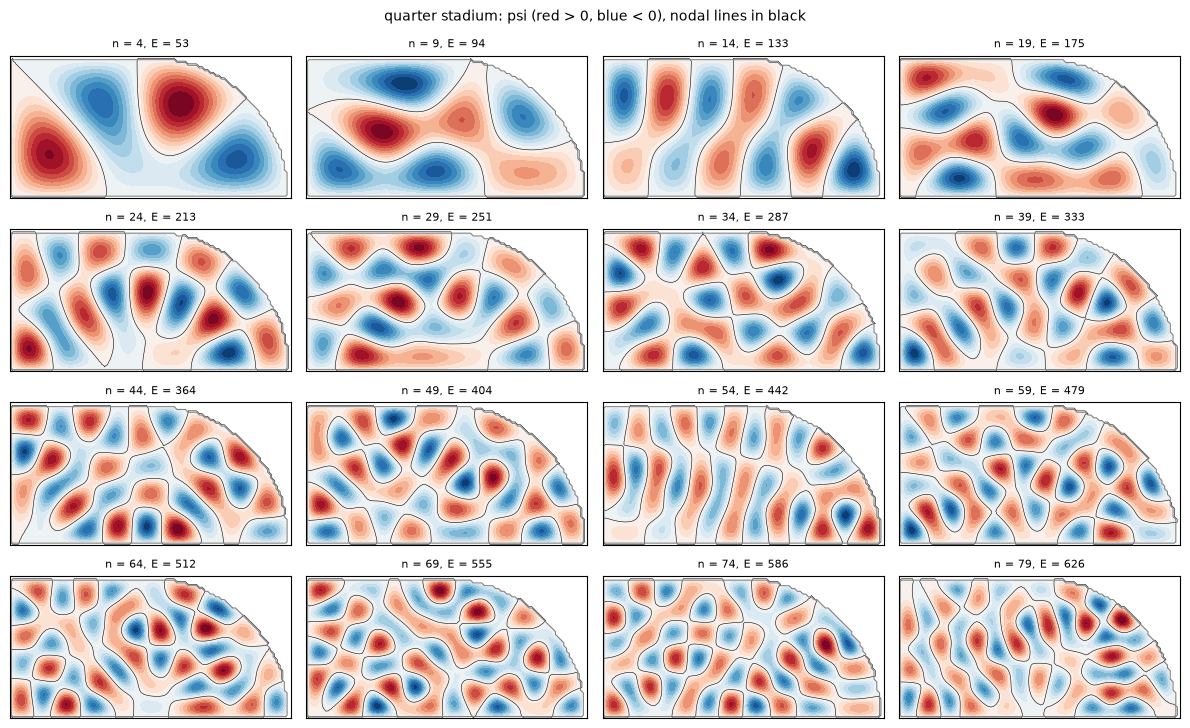

In [7]:
Xq0, Yq0 = grid(2, 1, h_st, quarter=True)
mask_q0 = quarter_stadium_mask(Xq0, Yq0)
E_q0, psi_q0 = solve(mask_q0, h_st, 80)
inside = E_q0 < E_st[-1]
match = np.array([np.min(np.abs(E_st / e - 1)) for e in E_q0[inside]])
print(f"quarter stadium, h = {h_st}: {mask_q0.sum()} unknowns; {inside.sum()} of its levels lie below E = {E_st[-1]:.0f}"
      f" (the full stadium has 300 there, ratio {inside.sum() / 300:.2f})")
print(f"each matched to the nearest full-stadium level: worst relative mismatch {match.max():.1e}")
check("6pre (quarter-stadium levels are a subset of the full spectrum, rtol 1e-9)", match.max() < 1e-9)

show = np.arange(0, 80, 5)[:16] + 4
fig, axes = plt.subplots(4, 4, figsize=(12, 7.5))
for ax, n in zip(axes.flat, show):
    p = np.where(mask_q0, psi_q0[n], np.nan)
    vmax = np.nanmax(np.abs(p))
    ax.contourf(Xq0, Yq0, p, levels=np.linspace(-vmax, vmax, 21), cmap="RdBu_r")
    ax.contour(Xq0, Yq0, np.where(mask_q0, psi_q0[n], 0), levels=[0], colors="k", linewidths=0.4)
    ax.contour(Xq0, Yq0, mask_q0.astype(float), levels=[0.5], colors="gray", linewidths=0.8)
    ax.set_aspect("equal"); ax.set_xticks([]); ax.set_yticks([])
    ax.set_title(f"n = {n}, E = {E_q0[n]:.0f}", fontsize=8)
plt.suptitle("quarter stadium: psi (red > 0, blue < 0), nodal lines in black", fontsize=10)
plt.tight_layout()
plt.show()

Each spectrum below is 1000 levels (`eigenvalues` solves in windows of 150 around moving shifts).
At the top level there are about 15 grid points per wavelength (about 11 on the coarser check grid).

In [8]:
h_q = 0.005
Xq, Yq = grid(2, 1, h_q, quarter=True)
E_q = eigenvalues(quarter_stadium_mask(Xq, Yq), h_q, 1000)

h_rr = 0.0073                                  # 233 x 144 rectangle with about the same area
E_rr = eigenvalues(rectangle_mask(Nx, Ny), h_rr, 1000)
dev = np.max(np.abs(E_rr / rect_exact_discrete(Nx, Ny, h_rr, 1000) - 1))
print(f"windowed solver on the rectangle, 1000 levels: max deviation from exact = {dev:.1e}")
check("6a (windowed eigenvalues = exact discrete, rtol 1e-9)", dev < 1e-9)

A_q, L_q = stadium_area(quarter=True), quarter_stadium_perimeter()
A_rr, L_rr = Nx * Ny * h_rr**2, 2 * (Nx + Ny) * h_rr
S = {
    ("rectangle", "Weyl"): spacings(unfold_weyl(E_rr, A_rr, L_rr)),
    ("rectangle", "fit"): spacings(unfold_fit(E_rr)),
    ("quarter stadium", "Weyl"): spacings(unfold_weyl(E_q, A_q, L_q)),
    ("quarter stadium", "fit"): spacings(unfold_fit(E_q)),
}
C = {key: compare(s) for key, s in S.items()}
print(f"{'':28s} {'<s>':>6s} {'D_Poi':>6s} {'p_Poi':>8s} {'D_Wig':>6s} {'p_Wig':>8s} {'P(s<0.1)':>9s}")
for (shape, how), c in C.items():
    print(f"{shape + ' / ' + how:28s} {c['mean']:6.3f} {c['D_poisson']:6.3f} {c['p_poisson']:8.1e} "
          f"{c['D_wigner']:6.3f} {c['p_wigner']:8.1e} {c['small']:9.4f}")
print(f"{'expected':28s} {1:6.3f} {'':6s} {'':8s} {'':6s} {'':8s}  Poi 0.0952 / Wig 0.0078")

windowed solver on the rectangle, 1000 levels: max deviation from exact = 8.4e-14
CHECK 6a (windowed eigenvalues = exact discrete, rtol 1e-9): PASS
                                <s>  D_Poi    p_Poi  D_Wig    p_Wig  P(s<0.1)
rectangle / Weyl              0.972  0.019  8.7e-01  0.230  1.3e-44    0.1085
rectangle / fit               0.997  0.028  4.5e-01  0.222  1.9e-41    0.1085
quarter stadium / Weyl        0.986  0.204  5.0e-35  0.047  3.1e-02    0.0042
quarter stadium / fit         0.999  0.208  1.8e-36  0.038  1.3e-01    0.0042
expected                      1.000                                  Poi 0.0952 / Wig 0.0078


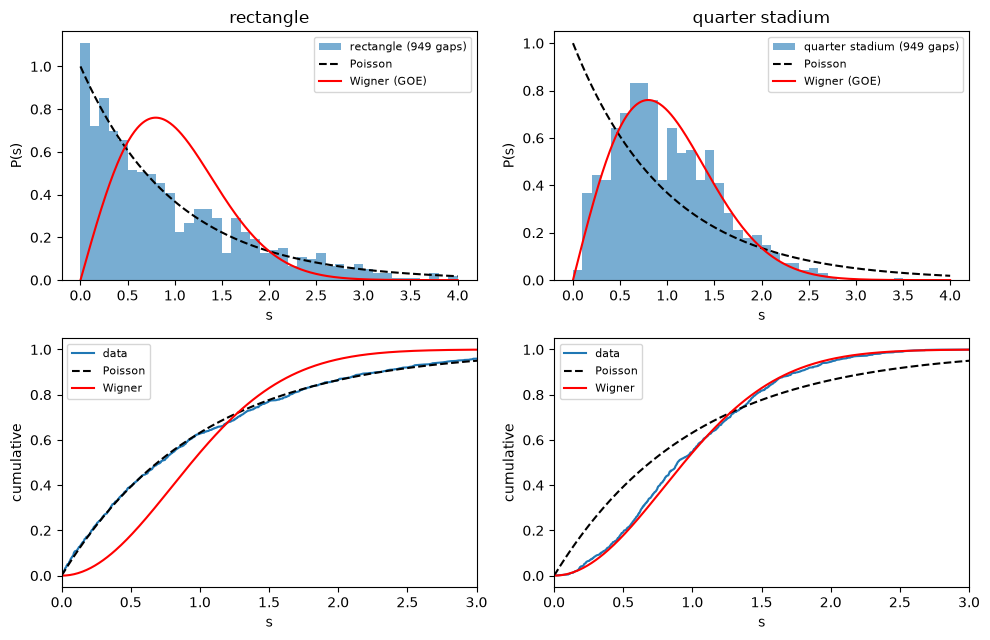

CHECK 6b (rectangle: Poisson accepted p > 0.01, Wigner rejected p < 1e-6): PASS
CHECK 6c (quarter stadium: Wigner accepted p > 0.01, Poisson rejected p < 1e-6): PASS
CHECK 6d (both unfoldings give the same verdicts; fitted <s> = 1 +- 0.01): PASS


In [9]:
s_grid = np.linspace(0, 4, 400)
fig, axes = plt.subplots(2, 2, figsize=(10, 6.5))
for col, shape in enumerate(("rectangle", "quarter stadium")):
    s = S[(shape, "fit")]
    ax = axes[0, col]
    ax.hist(s, bins=40, range=(0, 4), density=True, alpha=0.6, label=f"{shape} ({len(s)} gaps)")
    ax.plot(s_grid, poisson_pdf(s_grid), "k--", label="Poisson")
    ax.plot(s_grid, wigner_pdf(s_grid), "r-", label="Wigner (GOE)")
    ax.set(xlabel="s", ylabel="P(s)", title=shape); ax.legend(fontsize=8)
    ax = axes[1, col]
    ax.plot(np.sort(s), np.arange(1, len(s) + 1) / len(s), label="data")
    ax.plot(s_grid, poisson_cdf(s_grid), "k--", label="Poisson")
    ax.plot(s_grid, wigner_cdf(s_grid), "r-", label="Wigner")
    ax.set(xlabel="s", ylabel="cumulative", xlim=(0, 3)); ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

rect, stad = C[("rectangle", "fit")], C[("quarter stadium", "fit")]
check("6b (rectangle: Poisson accepted p > 0.01, Wigner rejected p < 1e-6)",
      rect["p_poisson"] > 0.01 and rect["p_wigner"] < 1e-6)
check("6c (quarter stadium: Wigner accepted p > 0.01, Poisson rejected p < 1e-6)",
      stad["p_wigner"] > 0.01 and stad["p_poisson"] < 1e-6)
check("6d (both unfoldings give the same verdicts; fitted <s> = 1 +- 0.01)",
      all(abs(C[(sh, "fit")]["mean"] - 1) < 0.01 for sh in ("rectangle", "quarter stadium"))
      and all((C[(sh, "Weyl")]["p_poisson"] > 0.01) == (C[(sh, "fit")]["p_poisson"] > 0.01)
              and (C[(sh, "Weyl")]["p_wigner"] > 0.01) == (C[(sh, "fit")]["p_wigner"] > 0.01)
              for sh in ("rectangle", "quarter stadium")))

**Is the verdict a grid artifact?** The staircased arc is the main discretization error. Re-solve
the quarter stadium on a coarser grid. Its levels move a little, and the statistics should not.

In [10]:
h_q2 = 0.0065
Xq2, Yq2 = grid(2, 1, h_q2, quarter=True)
E_q2 = eigenvalues(quarter_stadium_mask(Xq2, Yq2), h_q2, 1000)
c2 = compare(spacings(unfold_fit(E_q2)))
shift = np.median(np.abs(E_q2[50:] / E_q[50:] - 1))
print(f"h = {h_q2}: median level shift vs h = {h_q} is {shift:.1e}")
print(f"h = {h_q2}: p_Poisson = {c2['p_poisson']:.1e}, p_Wigner = {c2['p_wigner']:.2f}, P(s<0.1) = {c2['small']:.4f}")
print(f"h = {h_q}:  p_Poisson = {stad['p_poisson']:.1e}, p_Wigner = {stad['p_wigner']:.2f}, P(s<0.1) = {stad['small']:.4f}")
check("6e (coarser grid: same verdict)", c2["p_wigner"] > 0.01 and c2["p_poisson"] < 1e-6)

h = 0.0065: median level shift vs h = 0.005 is 5.4e-03
h = 0.0065: p_Poisson = 3.1e-32, p_Wigner = 0.24, P(s<0.1) = 0.0021
h = 0.005:  p_Poisson = 1.8e-36, p_Wigner = 0.13, P(s<0.1) = 0.0042
CHECK 6e (coarser grid: same verdict): PASS


## 7. Summary of checks

In [11]:
for name, ok in checks.items():
    print(f"{'PASS' if ok else 'FAIL'}  {name}")
print(f"\n{sum(checks.values())}/{len(checks)} passed")

PASS  1 (slicing residual < 1e-8 for every state)
PASS  2a (solver = exact discrete spectrum, rtol 1e-9)
PASS  2b (convergence order 2 +- 0.05)
PASS  4 (rectangle I A = 9/4 to 1e-6)
PASS  5 (>= half of the top 20 scarred, both orbits present, top-20 rate > 2x overall)
PASS  6pre (quarter-stadium levels are a subset of the full spectrum, rtol 1e-9)
PASS  6a (windowed eigenvalues = exact discrete, rtol 1e-9)
PASS  6b (rectangle: Poisson accepted p > 0.01, Wigner rejected p < 1e-6)
PASS  6c (quarter stadium: Wigner accepted p > 0.01, Poisson rejected p < 1e-6)
PASS  6d (both unfoldings give the same verdicts; fitted <s> = 1 +- 0.01)
PASS  6e (coarser grid: same verdict)

11/11 passed
